# Figure 1C — CAID3 Disorder-PDB: MCC ranking (top 40)

The 40 best CAID3 disorder predictors ranked by per-residue MCC on the CAID3 Disorder-PDB reference set, with metapredict V1, V2 and V3 highlighted.

**How it is made.** Every MCC is recomputed here from the CAID3 submission files (`data/caid3/*.caid` in the shared data directory) using the same readers as 1B, so all three CAID panels are scored the same way. Each method is scored on its own submitted binary calls; raw-score-only methods are thresholded at 0.5 (AlphaFold RSA 0.581, AlphaFold pLDDT 0.312). metapredict V1–V3 are scored from metapredict 3.1.0 predictions of the CAID3 targets (`data/metapredict_caid/`), using 3.1.0's default binary calls (residues inside predicted IDRs are disordered), instead of the metapredict files distributed by CAID3. The list of disorder predictors (binding predictors excluded) is taken from `data/caid_references/caid3_disorder_pdb_results.csv`; only the names are used from that file. Its MCC column is the CAID3 pipeline's MCC at the Fmax threshold, which is shown in Figure S3D.

**Output:** `figures/figure_1C.pdf`

In [1]:
import csv

import matplotlib.pyplot as plt

from caid_mcc import (CAID3_CUTOFF_OVERRIDES, CAID3_METAPREDICT_NAMES, DEFAULT_CUTOFF,
                      caid3_has_binarized_scores, metapredict_mcc, plot_mcc_panel,
                      read_caid_convert_get_MCC, read_caid_convert_get_MCC_allow_altered_cutoff,
                      read_caid_seq_disorder)
from figtools import apply_style, require_metapredict_3_1, save_panel, shared_data_path

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

TOP_N = 40

CAID3_DIR = shared_data_path('caid3')
caid3_dat = read_caid_seq_disorder(str(shared_data_path('caid_references', 'caid3_disorder_pdb.fasta')))

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
# disorder predictors in the CAID3 disorder ranking (names only)
with open(shared_data_path('caid_references', 'caid3_disorder_pdb_results.csv')) as fh:
    caid3_predictors = [row['predictor'] for row in csv.DictReader(fh)]

# score each predictor on its own binary calls if it has them, else threshold raw scores;
# metapredict is scored separately from the 3.1.0 predictions
caid3_disprot_pdb_mcc = metapredict_mcc('caid3', caid3_dat)
for name in caid3_predictors:
    if name in CAID3_METAPREDICT_NAMES:
        continue
    caid_file = CAID3_DIR / f'{name}.caid'
    if caid3_has_binarized_scores(caid_file):
        mcc = read_caid_convert_get_MCC(caid_file, caid3_dat)
    else:
        cutoff = CAID3_CUTOFF_OVERRIDES.get(name, DEFAULT_CUTOFF)
        mcc = read_caid_convert_get_MCC_allow_altered_cutoff(caid_file, caid3_dat, cutoff=cutoff)
    caid3_disprot_pdb_mcc[name] = mcc

print(f'{len(caid3_disprot_pdb_mcc)} predictors scored')
for name in CAID3_METAPREDICT_NAMES.values():
    rank = sorted(caid3_disprot_pdb_mcc, key=caid3_disprot_pdb_mcc.get, reverse=True).index(name) + 1
    print(f'{name}: MCC = {caid3_disprot_pdb_mcc[name]:.3f} (rank {rank})')

66 predictors scored
metapredict V1: MCC = 0.688 (rank 24)
metapredict V2: MCC = 0.741 (rank 9)
metapredict V3: MCC = 0.756 (rank 7)


Wrote figures/figure_1C.pdf


PosixPath('figures/figure_1C.pdf')

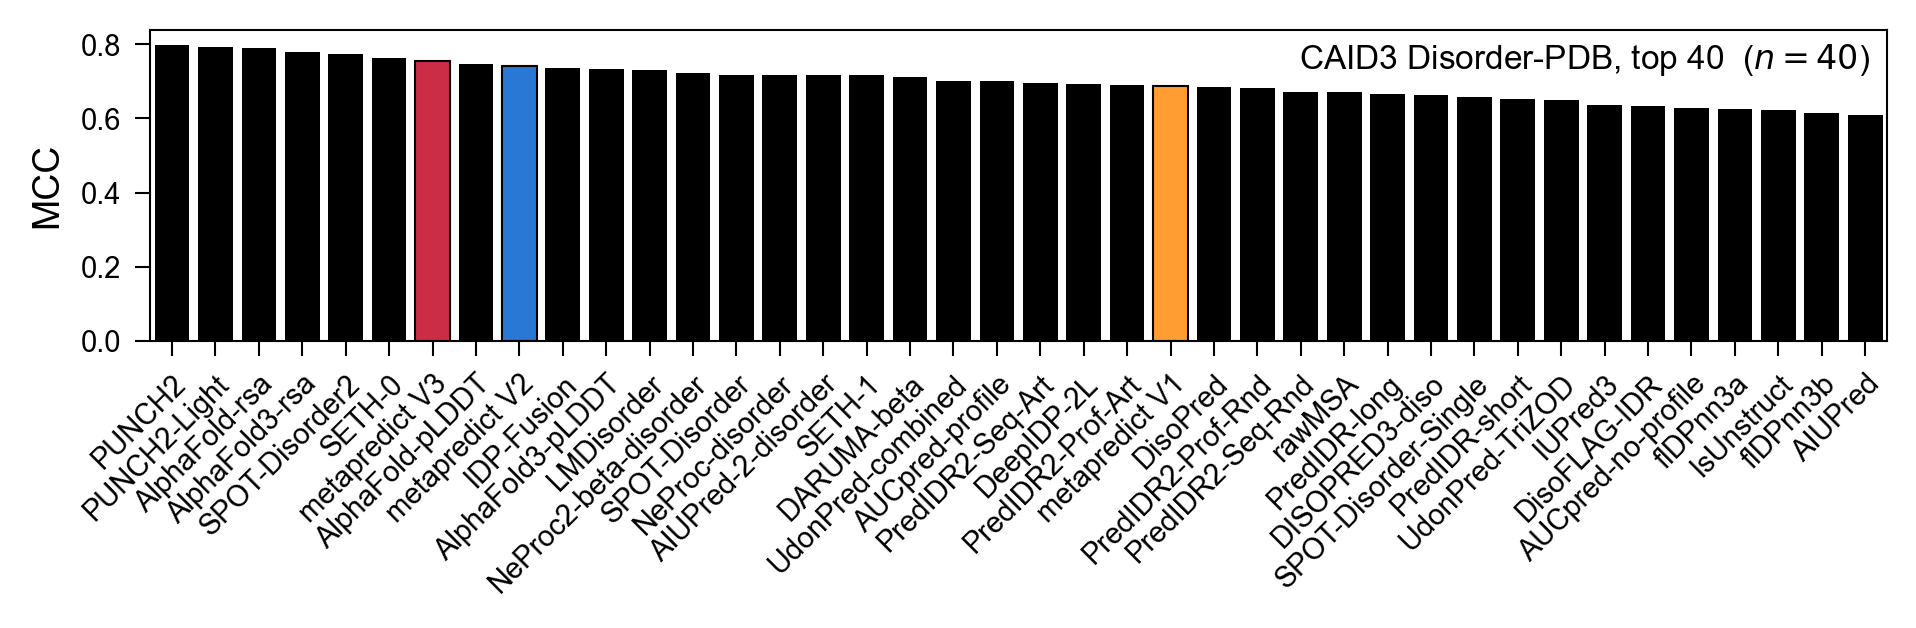

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 2.2), dpi=150)
plot_mcc_panel(ax, caid3_disprot_pdb_mcc, f'CAID3 Disorder-PDB, top {TOP_N}', top_n=TOP_N)
plt.tight_layout()
save_panel(fig, 'figure_1C')